# 2. Log-likelihood landscapes for simple models

Portfolio exercises [MLE 1.3.6–1.4, 1.6.2]. Each exercise plots a
log-likelihood as a function of its parameters, locates the ML estimate and
checks the calculus behind it numerically: gradients against finite
differences, Hessians by the signs of their eigenvalues, matrix derivatives by
directional differences. All random experiments use
`rng = np.random.default_rng(2026)`.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln
from scipy.optimize import minimize, minimize_scalar, linprog

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

## 2.1 Univariate Gaussian: a two-parameter landscape [MLE 1.3.6]

### Task

Sample $m=20$ points from $N(\mu=1,\sigma^2=4)$ and plot the surface and the
contour lines of

$$\ell(\mu,\sigma^2)=-\frac{m}{2}\log(2\pi)-\frac{m}{2}\log\sigma^2
-\frac{1}{2\sigma^2}\sum_i (y_i-\mu)^2$$

over a grid of $(\mu,\sigma^2)$. Mark the true parameters and
$(\hat\mu_{\mathrm{ML}},\hat\sigma^2_{\mathrm{ML}})$, and draw the gradient
field $\nabla\ell$ as arrows.

### Explore

Increase $m$ to 200 and 2,000. Plot the slice $\ell(\mu,\hat\sigma^2_{\mathrm{ML}})$
and the slice $\ell(\hat\mu_{\mathrm{ML}},\sigma^2)$. Repeat the plot with
$\log\sigma^2$ on the vertical axis.

In [20]:
m = 20
mu_true, var_true = 1.0, 4.0
y = rng.normal(mu_true, np.sqrt(var_true), size=m)


def loglik_gauss(mu, var, y=y):
    '''Gaussian log-likelihood l(mu, var), broadcast over arrays mu, var.'''
    y = np.asarray(y, dtype=float)
    n = y.size
    mu = np.asarray(mu, dtype=float)
    var = np.asarray(var, dtype=float)
    mu, var = np.broadcast_arrays(mu, var)
    r = y.reshape((-1,) + (1,) * mu.ndim) - mu
    return (-0.5 * n * np.log(2 * np.pi) - 0.5 * n * np.log(var)
            - np.sum(r ** 2, axis=0) / (2 * var))


def grad_gauss(mu, var, y=y):
    y = np.asarray(y, dtype=float)
    n = y.size
    r = y - mu
    return np.array([np.sum(r) / var,
                     -n / (2 * var) + np.sum(r ** 2) / (2 * var ** 2)])


def hess_gauss(mu, var, y=y):
    y = np.asarray(y, dtype=float)
    n = y.size
    r = y - mu
    h11, h12 = -n / var, -np.sum(r) / var ** 2
    h22 = n / (2 * var ** 2) - np.sum(r ** 2) / var ** 3
    return np.array([[h11, h12], [h12, h22]])


mu_hat, var_hat = y.mean(), np.mean((y - y.mean()) ** 2)
p_hat = np.array([mu_hat, var_hat])
print(f"m = {m},  mu_hat = {mu_hat:.4f} (true {mu_true}),"
      f"  var_hat = {var_hat:.4f} (true {var_true})")
print("gradient at the ML point:", grad_gauss(*p_hat))


def fd_jac(fun, p, h=1e-5):
    '''Jacobian of fun at p by central differences.'''
    return np.column_stack([(fun(p + h * e) - fun(p - h * e)) / (2 * h)
                            for e in np.eye(p.size)])


# gradient: analytic vs finite differences, and zero at the ML point
g_fd = fd_jac(lambda p: loglik_gauss(p[0], p[1]), p_hat)
assert np.allclose(grad_gauss(*p_hat), g_fd, atol=1e-6)
assert np.allclose(grad_gauss(*p_hat), 0, atol=1e-12)

# Hessian: analytic vs finite differences of the gradient, negative definite
H = hess_gauss(*p_hat)
H_fd = fd_jac(lambda p: grad_gauss(p[0], p[1]), p_hat)
assert np.allclose(H, H_fd, atol=1e-4)
eig = np.linalg.eigvalsh(H)
print("Hessian at the ML point:", np.round(H, 3).tolist())
print("its eigenvalues:", np.round(eig, 4))
assert np.all(eig < 0), "the Hessian at the ML point must be negative definite"


m = 20,  mu_hat = 0.8063 (true 1.0),  var_hat = 2.0832 (true 4.0)
gradient at the ML point: [-4.26352108e-16 -8.88178420e-16]
Hessian at the ML point: [[-9.601, 0.0], [0.0, -2.304]]
its eigenvalues: [-9.6006 -2.3043]


In [21]:
# mu_hat is the same for every fixed sigma^2
mu_sol = np.array([minimize_scalar(lambda mu: -loglik_gauss(mu, v), bounds=(-3, 5),
                                   method="bounded", options={"xatol": 1e-12}).x
                   for v in [0.5, 1.0, 2.0, 4.0, 8.0, 16.0]])
print("argmax over mu, for sigma^2 = 0.5 ... 16:", np.round(mu_sol, 6))
assert np.allclose(mu_sol, mu_hat, atol=1e-6)

# while the sigma^2 maximiser at fixed mu is S(mu)/m
mu_test = np.array([0.0, 0.5, 1.0, 2.0, 3.0])
var_sol = np.array([minimize_scalar(lambda v: -loglik_gauss(mu, v), bounds=(1e-3, 80),
                                    method="bounded", options={"xatol": 1e-12}).x
                    for mu in mu_test])
S_mu = np.sum((y[None, :] - mu_test[:, None]) ** 2, axis=1)
print("mu         :", np.round(mu_test, 2))
print("argmax s^2 :", np.round(var_sol, 3))
print("S(mu)/m    :", np.round(S_mu / m, 3))
assert np.allclose(var_sol, S_mu / m, rtol=1e-6)

# where is the Hessian negative semidefinite in (mu, sigma^2)?
mus_c = np.linspace(-1.0, 3.0, 9)
vars_c = np.linspace(0.5, 9.0, 18)
assert np.abs(vars_c - 2 * var_hat).min() > 0.05   # no grid point on the boundary
negdef = np.array([[np.linalg.eigvalsh(hess_gauss(a, b)).max() < 0
                    for b in vars_c] for a in mus_c])
assert np.array_equal(negdef, np.tile(vars_c < 2 * var_hat, (mus_c.size, 1)))
print(f"2*var_hat = {2 * var_hat:.4f}: Hessian negative definite exactly for sigma^2 < 2*var_hat")

# same question in the precision parametrisation tau = 1/sigma^2
def hess_gauss_tau(mu, tau, y=y):
    y = np.asarray(y, dtype=float)
    n = y.size
    return np.array([[-n * tau, np.sum(y - mu)],
                     [np.sum(y - mu), -n / (2 * tau ** 2)]])


tau_hat = 1 / var_hat
print("eigenvalues in (mu, tau) at the ML point:",
      np.round(np.linalg.eigvalsh(hess_gauss_tau(mu_hat, tau_hat)), 3))
grid_mu = np.linspace(mu_hat - 3, mu_hat + 3, 13)
grid_tau = np.geomspace(0.5 * tau_hat, 4 * tau_hat, 13)
nsd_tau = np.array([[np.linalg.eigvalsh(hess_gauss_tau(a, b)).max() < 0
                     for b in grid_tau] for a in grid_mu])
pred_tau = np.abs(grid_mu[:, None] - mu_hat) < 1 / np.sqrt(2 * grid_tau)[None, :]
assert np.array_equal(nsd_tau, pred_tau)
print("in (mu, tau): negative definite exactly for |mu - mu_hat| < 1/sqrt(2 tau)")

# and in (mu, log sigma^2)
def hess_gauss_logvar(mu, t, y=y):
    y = np.asarray(y, dtype=float)
    n = y.size
    S = np.sum((y - mu) ** 2)
    return np.exp(-t) * np.array([[-n, -np.sum(y - mu)],
                                  [-np.sum(y - mu), -S / 2]])


grid_t = np.linspace(np.log(0.5 * var_hat), np.log(4 * var_hat), 13)
nsd_t = np.array([[np.linalg.eigvalsh(hess_gauss_logvar(a, b)).max() < 0
                   for b in grid_t] for a in grid_mu])
pred_t = np.broadcast_to(
    (np.abs(grid_mu - mu_hat) < np.sqrt(var_hat))[:, None], nsd_t.shape)
assert np.array_equal(nsd_t, pred_t)
print("in (mu, log sigma^2): negative definite exactly for |mu - mu_hat| < sigma_hat")


argmax over mu, for sigma^2 = 0.5 ... 16: [0.806313 0.806313 0.806313 0.806313 0.806313 0.806313]
mu         : [0.  0.5 1.  2.  3. ]
argmax s^2 : [2.733 2.177 2.121 3.508 6.895]
S(mu)/m    : [2.733 2.177 2.121 3.508 6.895]
2*var_hat = 4.1664: Hessian negative definite exactly for sigma^2 < 2*var_hat
eigenvalues in (mu, tau) at the ML point: [-43.397  -9.601]
in (mu, tau): negative definite exactly for |mu - mu_hat| < 1/sqrt(2 tau)
in (mu, log sigma^2): negative definite exactly for |mu - mu_hat| < sigma_hat


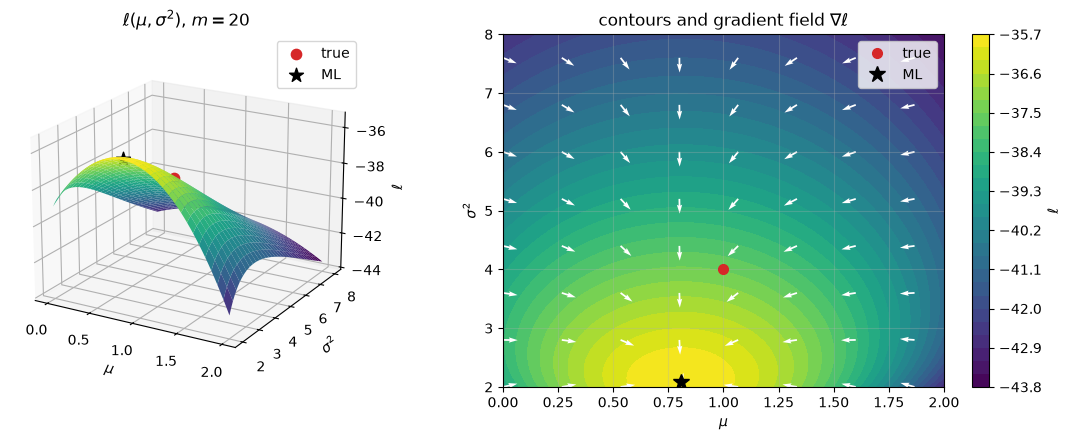

In [22]:
mus_f = np.linspace(0.0, 2.0, 121)
vars_f = np.linspace(2.0, 8.0, 121)
MUf, VARf = np.meshgrid(mus_f, vars_f, indexing="ij")
Lf = loglik_gauss(MUf, VARf)

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(MUf[::2, ::2], VARf[::2, ::2], Lf[::2, ::2], cmap="viridis",
                linewidth=0, antialiased=True)
ax.scatter([mu_true], [var_true], [loglik_gauss(mu_true, var_true)],
           color="tab:red", s=55, label="true")
ax.scatter([mu_hat], [var_hat], [loglik_gauss(mu_hat, var_hat)],
           color="k", s=110, marker="*", label="ML")
ax.set_xlabel(r"$\mu$"); ax.set_ylabel(r"$\sigma^2$"); ax.set_zlabel(r"$\ell$")
ax.view_init(elev=20, azim=-60)
ax.legend(loc="upper right")
ax.set_title(r"$\ell(\mu,\sigma^2)$, $m=20$")

ax = fig.add_subplot(1, 2, 2)
cs = ax.contourf(MUf, VARf, Lf, levels=30, cmap="viridis")
fig.colorbar(cs, ax=ax, label=r"$\ell$")
step = 16
gm = m * (mu_hat - MUf[::step, ::step]) / VARf[::step, ::step]
gv = (-m / (2 * VARf[::step, ::step])
      + np.sum((y.reshape(-1, 1, 1) - MUf[::step, ::step]) ** 2, axis=0)
      / (2 * VARf[::step, ::step] ** 2))
norm = np.hypot(gm, gv)
ax.quiver(MUf[::step, ::step], VARf[::step, ::step], gm / norm, gv / norm,
          color="w", scale=30, width=0.004)
ax.plot(mu_true, var_true, "o", color="tab:red", ms=7, label="true")
ax.plot(mu_hat, var_hat, "*", color="k", ms=12, label="ML")
ax.set_xlabel(r"$\mu$"); ax.set_ylabel(r"$\sigma^2$")
ax.set_title(r"contours and gradient field $\nabla\ell$")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

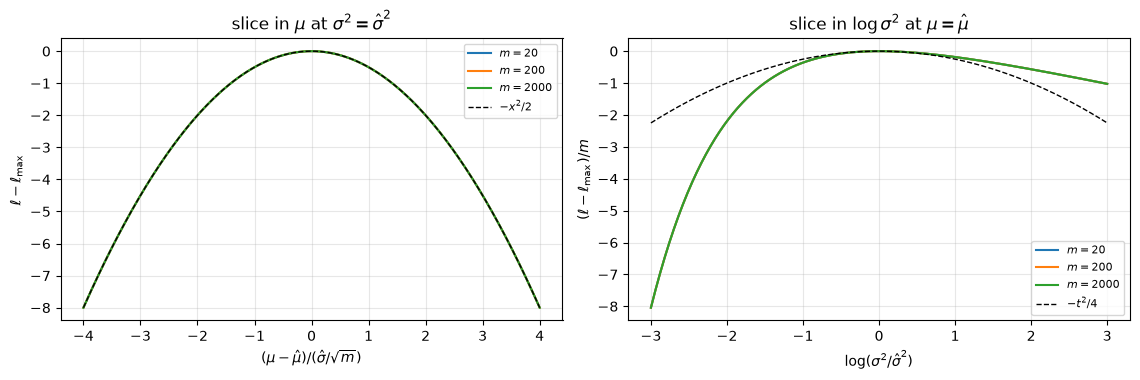

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
for mm, color in zip([20, 200, 2000], ["tab:blue", "tab:orange", "tab:green"]):
    yy = rng.normal(mu_true, np.sqrt(var_true), size=mm)
    mh, vh = yy.mean(), np.mean((yy - yy.mean()) ** 2)
    se = np.sqrt(vh / mm)
    gm = np.linspace(mh - 4 * se, mh + 4 * se, 400)
    axes[0].plot((gm - mh) / se,
                 loglik_gauss(gm, vh, y=yy) - loglik_gauss(mh, vh, y=yy),
                 color=color, label=f"$m={mm}$")
    t = np.linspace(np.log(vh) - 3, np.log(vh) + 3, 400)
    axes[1].plot(t - np.log(vh),
                 (loglik_gauss(mh, np.exp(t), y=yy) - loglik_gauss(mh, vh, y=yy)) / mm,
                 color=color, label=f"$m={mm}$")

xq = np.linspace(-4, 4, 200)
axes[0].plot(xq, -0.5 * xq ** 2, "k--", lw=1, label=r"$-x^2/2$")
tq = np.linspace(-3, 3, 200)
axes[1].plot(tq, -0.25 * tq ** 2, "k--", lw=1, label=r"$-t^2/4$")
axes[0].set_xlabel(r"$(\mu-\hat\mu)/(\hat\sigma/\sqrt{m})$")
axes[0].set_ylabel(r"$\ell-\ell_{\max}$")
axes[0].set_title(r"slice in $\mu$ at $\sigma^2=\hat\sigma^2$")
axes[0].legend(fontsize=8)
axes[1].set_xlabel(r"$\log(\sigma^2/\hat\sigma^2)$")
axes[1].set_ylabel(r"$(\ell-\ell_{\max})/m$")
axes[1].set_title(r"slice in $\log\sigma^2$ at $\mu=\hat\mu$")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Explain

The gradient vanishes at the ML point $(-4.3\times10^{-16},\,-8.9\times10^{-16})$. The Hessian there is
$\mathrm{diag}(-9.601,-2.304)$ (off-diagonal entries $2\times10^{-16}$), both
eigenvalues negative, so $(\hat\mu,\hat\sigma^2)_{\mathrm{ML}}$ is a strict
local maximum.

$\hat\mu_{\mathrm{ML}}$ does not depend on $\sigma^2$ because
$\partial\ell/\partial\mu=\sum_i(y_i-\mu)/\sigma^2$ vanishes at $\mu=\bar y$
for every $\sigma^2$. On the other hand $\sigma^2_{\mathrm{ML}}$ depends on $\mu$ because $\partial\ell/\partial\sigma^2=-m/(2\sigma^2)+S(\mu)/(2\sigma^4)$
vanishes at $\sigma^2=S(\mu)/m$.


## 2.2 The bias of $\hat\sigma^2_{\mathrm{ML}}$ [MLE 1.3.6, 1.5]

### Task

Simulate 50,000 data sets of size $m$ from $N(0,1)$ and plot the histograms of

$$\hat\sigma^2_{\mathrm{ML}}=\frac{1}{m}\sum_i(y_i-\hat\mu_{\mathrm{ML}})^2
\quad\text{and}\quad
\frac{1}{m-1}\sum_i(y_i-\hat\mu_{\mathrm{ML}})^2 .$$

Plot $E(\hat\sigma^2_{\mathrm{ML}})$, the variance and the MSE of both
estimators against $m$, using $E(\hat\sigma^2_{\mathrm{ML}})=\frac{m-1}{m}\sigma^2$
and $\mathrm{MSE}=b^2+\mathrm{Var}$.

### Explore

Compare the histogram of $m\hat\sigma^2_{\mathrm{ML}}/\sigma^2$ with a
$\chi^2_{m-1}$ density.

In [24]:
ms = np.array([2, 3, 5, 10, 20, 50, 100])
R = 50_000
E_ml, V_ml, E_un, V_un = [], [], [], []
samples = {}
for mm in ms:
    yy = rng.normal(0.0, 1.0, size=(R, mm))
    ss = ((yy - yy.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
    ml, un = ss / mm, ss / (mm - 1)
    samples[mm] = (ml, un)
    E_ml.append(ml.mean()); V_ml.append(ml.var(ddof=1))
    E_un.append(un.mean()); V_un.append(un.var(ddof=1))
E_ml, V_ml, E_un, V_un = map(np.array, (E_ml, V_ml, E_un, V_un))
mse_ml = V_ml + (E_ml - 1) ** 2
mse_un = V_un + (E_un - 1) ** 2

print("  m   E[s2_ML]   (m-1)/m   Var[s2_ML]  2(m-1)/m^2   MSE_ML  (2m-1)/m^2"
      "   MSE_unb   2/(m-1)  ratio")
for i, mm in enumerate(ms):
    print(f"{mm:3d}  {E_ml[i]:8.4f}  {(mm-1)/mm:8.4f}  {V_ml[i]:9.4f}  {2*(mm-1)/mm**2:9.4f}"
          f"  {mse_ml[i]:7.4f}  {(2*mm-1)/mm**2:10.4f}  {mse_un[i]:8.4f}  {2/(mm-1):7.4f}"
          f"  {mse_un[i]/mse_ml[i]:5.2f}")

assert np.allclose(E_ml, (ms - 1) / ms, rtol=0.02)
assert np.allclose(V_ml, 2 * (ms - 1) / ms ** 2, rtol=0.05)
assert np.allclose(mse_ml, (2 * ms - 1) / ms ** 2, rtol=0.05)
assert np.allclose(mse_un, 2 / (ms - 1), rtol=0.05)
assert np.all(mse_ml < mse_un)

for mm in (5, 20, 50):
    ks = stats.kstest(mm * samples[mm][0], "chi2", args=(mm - 1,))
    print(f"m = {mm:3d}: KS statistic {ks.statistic:.5f}, p-value {ks.pvalue:.3f}")
    assert ks.pvalue > 0.01

  m   E[s2_ML]   (m-1)/m   Var[s2_ML]  2(m-1)/m^2   MSE_ML  (2m-1)/m^2   MSE_unb   2/(m-1)  ratio
  2    0.4982    0.5000     0.4899     0.5000   0.7417      0.7500    1.9596   2.0000   2.64
  3    0.6669    0.6667     0.4467     0.4444   0.5577      0.5556    1.0050   1.0000   1.80
  5    0.8020    0.8000     0.3194     0.3200   0.3586      0.3600    0.4991   0.5000   1.39
 10    0.9003    0.9000     0.1826     0.1800   0.1926      0.1900    0.2254   0.2222   1.17
 20    0.9490    0.9500     0.0958     0.0950   0.0984      0.0975    0.1061   0.1053   1.08
 50    0.9799    0.9800     0.0393     0.0392   0.0397      0.0396    0.0409   0.0408   1.03
100    0.9915    0.9900     0.0198     0.0198   0.0198      0.0199    0.0202   0.0202   1.02
m =   5: KS statistic 0.00349, p-value 0.574
m =  20: KS statistic 0.00414, p-value 0.356
m =  50: KS statistic 0.00275, p-value 0.842


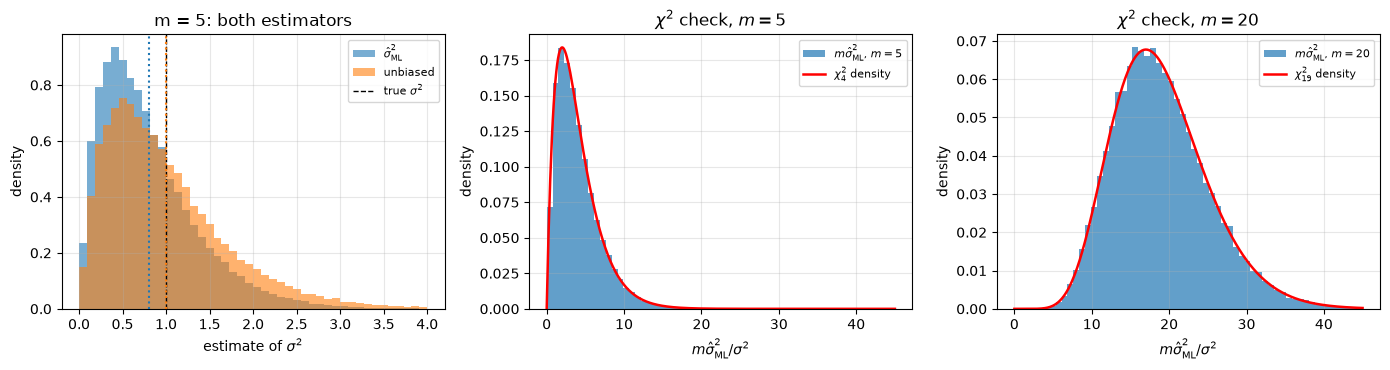

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
ml5, un5 = samples[5]
bins = np.linspace(0, 4, 45)
axes[0].hist(ml5, bins=bins, density=True, alpha=0.6, color="tab:blue",
             label=r"$\hat\sigma^2_{\rm ML}$")
axes[0].hist(un5, bins=bins, density=True, alpha=0.6, color="tab:orange",
             label="unbiased")
axes[0].axvline(1.0, color="k", ls="--", lw=1, label=r"true $\sigma^2$")
axes[0].axvline(ml5.mean(), color="tab:blue", ls=":", lw=1.5)
axes[0].axvline(un5.mean(), color="tab:orange", ls=":", lw=1.5)
axes[0].set_xlabel(r"estimate of $\sigma^2$"); axes[0].set_ylabel("density")
axes[0].set_title("m = 5: both estimators"); axes[0].legend(fontsize=8)

for ax, mm in zip(axes[1:], (5, 20)):
    ml, _ = samples[mm]
    ax.hist(mm * ml, bins=np.linspace(0, 45, 60), density=True, color="tab:blue",
            alpha=0.7, label=rf"$m\hat\sigma^2_{{\rm ML}}$, $m={mm}$")
    grid = np.linspace(1e-3, 45, 400)
    ax.plot(grid, stats.chi2.pdf(grid, mm - 1), "r-", lw=1.8,
            label=rf"$\chi^2_{{{mm-1}}}$ density")
    ax.set_xlabel(r"$m\hat\sigma^2_{\rm ML}/\sigma^2$"); ax.set_ylabel("density")
    ax.set_title(rf"$\chi^2$ check, $m={mm}$"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

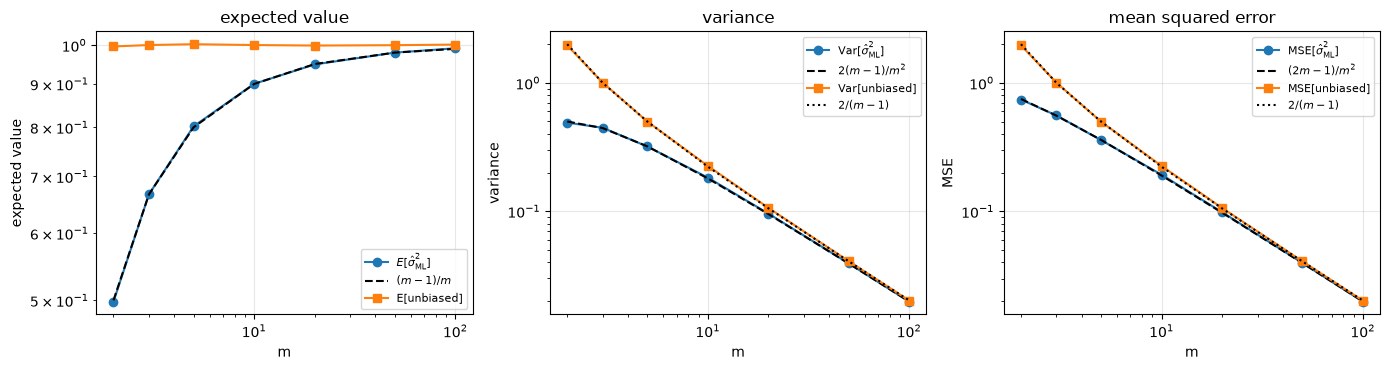

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].loglog(ms, E_ml, "o-", label=r"$E[\hat\sigma^2_{\rm ML}]$")
axes[0].loglog(ms, (ms - 1) / ms, "k--", label="$(m-1)/m$")
axes[0].loglog(ms, E_un, "s-", label="E[unbiased]")
axes[0].set_xlabel("m"); axes[0].set_ylabel("expected value")
axes[0].set_title("expected value"); axes[0].legend(fontsize=8)

axes[1].loglog(ms, V_ml, "o-", label=r"Var$[\hat\sigma^2_{\rm ML}]$")
axes[1].loglog(ms, 2 * (ms - 1) / ms ** 2, "k--", label="$2(m-1)/m^2$")
axes[1].loglog(ms, V_un, "s-", label="Var[unbiased]")
axes[1].loglog(ms, 2 / (ms - 1), "k:", label="$2/(m-1)$")
axes[1].set_xlabel("m"); axes[1].set_ylabel("variance")
axes[1].set_title("variance"); axes[1].legend(fontsize=8)

axes[2].loglog(ms, mse_ml, "o-", label=r"MSE$[\hat\sigma^2_{\rm ML}]$")
axes[2].loglog(ms, (2 * ms - 1) / ms ** 2, "k--", label="$(2m-1)/m^2$")
axes[2].loglog(ms, mse_un, "s-", label="MSE[unbiased]")
axes[2].loglog(ms, 2 / (ms - 1), "k:", label="$2/(m-1)$")
axes[2].set_xlabel("m"); axes[2].set_ylabel("MSE")
axes[2].set_title("mean squared error"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Explain

The $\sigma^2_\mathrm{ML}$  has the smaller MSE at every $m$ tested, and the gap is
largest for small $m$. This is the bias-variance
trade-off: the bias is $-\sigma^2/m$, so $b^2=\sigma^4/m^2$, while the variance
drops from $2\sigma^4/(m-1)$ to $2(m-1)\sigma^4/m^2$; at small $m$ the variance
saving is worth more than the bias.


## 2.3 Other one-parameter models [MLE 1.3.8, 1.3.9]

### Task

Derive $\hat\theta_{\mathrm{ML}}$ by hand and plot the normalised
log-likelihood $\frac1m\log p(y\mid\theta)$ for (a) Poisson
$p(y\mid\lambda)=e^{-\lambda}\lambda^y/y!$, (b) exponential
$f(y\mid\lambda)=\lambda e^{-\lambda y}$, (c) uniform on $[0,\theta]$, (d)
Gaussian with known $\sigma^2$ and unknown $\mu$. Use the same simulated $m$
for all four and put them in a $2\times2$ panel.

### Explore

Vary $m$ and the true parameter. Overlay the quadratic approximation of
[MLE 1.3.9],

$$\ell(\theta)\approx\ell(\hat\theta_{\mathrm{ML}})
-\frac{m}{2}I(\hat\theta_{\mathrm{ML}})(\theta-\hat\theta_{\mathrm{ML}})^2 .$$

In [27]:
m3 = 60
u = rng.uniform(size=m3)              # one set of uniforms, four models
y_pois = stats.poisson.ppf(u, 3.0)    # Poisson(lambda = 3)
y_exp = -np.log1p(-u) / 1.5           # exponential(rate 1.5)
y_unif = 2.0 * u                      # uniform[0, 2]
sig3 = 0.8
y_gauss = 1.0 + sig3 * stats.norm.ppf(u)   # N(1, 0.8^2)

lam_pois = y_pois.mean()
lam_exp = 1 / y_exp.mean()
th_unif = y_unif.max()
mu_gauss = y_gauss.mean()
print(f"m = {m3}")
print(f"Poisson     lambda_hat = {lam_pois:.4f}  (true 3)")
print(f"exponential lambda_hat = {lam_exp:.4f}  (true 1.5)")
print(f"uniform     theta_hat  = {th_unif:.4f}  (true 2)")
print(f"Gaussian    mu_hat     = {mu_gauss:.4f}  (true 1)")


def ll_pois(lam, y):
    return -lam + y.mean() * np.log(lam) - gammaln(y + 1).mean()


def ll_exp(lam, y):
    return np.log(lam) - lam * y.mean()


def ll_unif(theta, y):
    theta = np.asarray(theta, dtype=float)
    out = np.full(theta.shape, -np.inf)
    ok = theta >= y.max()
    out[ok] = -np.log(theta[ok])
    return out


def ll_gauss_mu(mu, y, sigma):
    mu = np.asarray(mu, dtype=float)
    r = y.reshape((-1,) + (1,) * mu.ndim) - mu
    return -0.5 * np.log(2 * np.pi * sigma ** 2) - np.mean(r ** 2, axis=0) / (2 * sigma ** 2)


# curvature at the maximum against the Fisher information per observation
def curvature(fun, x0, h):
    return (fun(x0 + h) - 2 * fun(x0) + fun(x0 - h)) / h ** 2


se_p = np.sqrt(lam_pois / m3)
se_e = lam_exp / np.sqrt(m3)
se_g = sig3 / np.sqrt(m3)
regular = [("Poisson", lambda t: ll_pois(t, y_pois), lam_pois, se_p, 1 / lam_pois),
           ("exponential", lambda t: ll_exp(t, y_exp), lam_exp, se_e, 1 / lam_exp ** 2),
           ("Gaussian", lambda t: ll_gauss_mu(t, y_gauss, sig3), mu_gauss, se_g,
            1 / sig3 ** 2)]
for name, fun, x0, se, info in regular:
    c = curvature(fun, x0, se / 50)
    print(f"{name:12s} curvature {c:9.6f}   -I(theta_hat) {-info:9.6f}"
          f"   rel.err {abs(c + info) / info:.1e}")
    assert np.isclose(c, -info, rtol=1e-4)

print("Poisson derivative at the estimate:", y_pois.mean() / lam_pois - 1)
print("exponential derivative at the estimate:", 1 / lam_exp - y_exp.mean())
print(f"uniform: l(theta_hat - eps) = {ll_unif(th_unif - 1e-6, y_unif)}")
assert np.isneginf(ll_unif(th_unif - 1e-6, y_unif))
h_u = 1e-7
slope_right = (ll_unif(th_unif + h_u, y_unif) - ll_unif(th_unif, y_unif)) / h_u
print(f"uniform: slope just right of theta_hat = {slope_right:.4f}"
      f"  (-1/theta_hat = {-1 / th_unif:.4f}), not 0")
assert np.isclose(slope_right, -1 / th_unif, rtol=1e-4)

for name, fun, x0, se, info in regular:
    for k in (2, 4):
        t = np.linspace(x0 - k * se, x0 + k * se, 400)
        err = np.abs(fun(t) - (fun(x0) - 0.5 * info * (t - x0) ** 2)).max()
        print(f"{name:12s} quadratic overlay: max |error| over +-{k} se = {err:.5f}"
              " (nats per observation)")

m = 60
Poisson     lambda_hat = 2.8500  (true 3)
exponential lambda_hat = 1.7346  (true 1.5)
uniform     theta_hat  = 1.9225  (true 2)
Gaussian    mu_hat     = 0.9525  (true 1)
Poisson      curvature -0.350878   -I(theta_hat) -0.350877   rel.err 1.2e-06
exponential  curvature -0.332343   -I(theta_hat) -0.332342   rel.err 3.3e-06
Gaussian     curvature -1.562500   -I(theta_hat) -1.562500   rel.err 6.6e-12
Poisson derivative at the estimate: 0.0
exponential derivative at the estimate: 0.0
uniform: l(theta_hat - eps) = -inf
uniform: slope just right of theta_hat = -0.5201  (-1/theta_hat = -0.5201), not 0
Poisson      quadratic overlay: max |error| over +-2 se = 0.00384 (nats per observation)
Poisson      quadratic overlay: max |error| over +-4 se = 0.03548 (nats per observation)
exponential  quadratic overlay: max |error| over +-2 se = 0.00714 (nats per observation)
exponential  quadratic overlay: max |error| over +-4 se = 0.07676 (nats per observation)
Gaussian     quadratic overlay: max

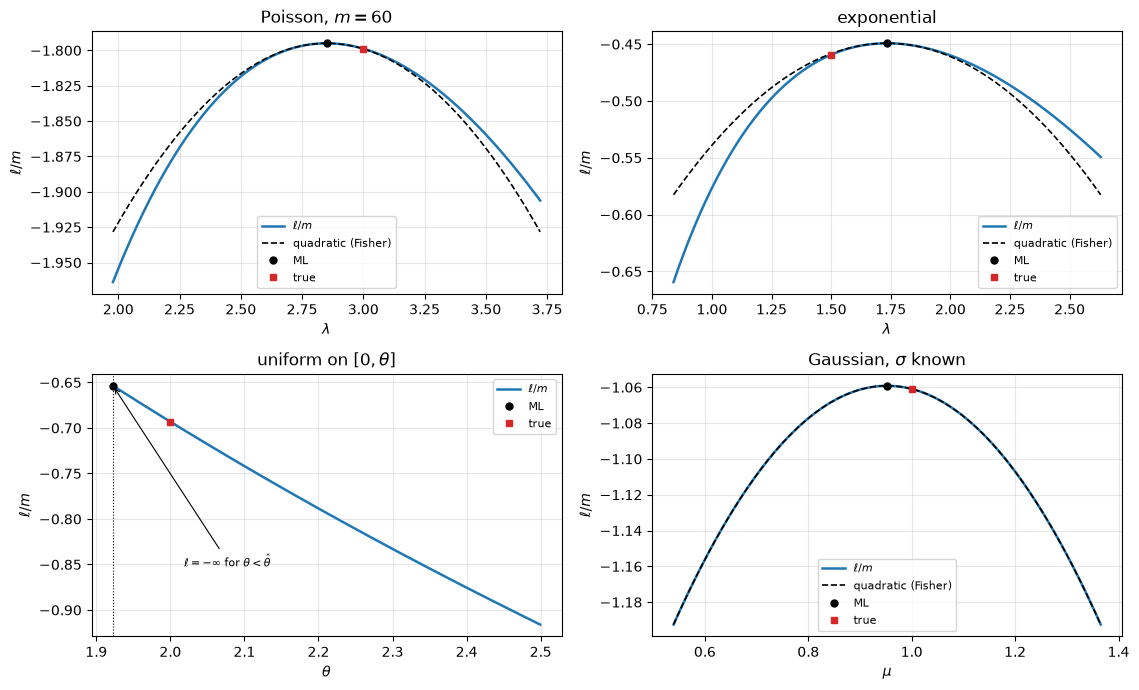

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.0))

grid = np.linspace(lam_pois - 4 * se_p, lam_pois + 4 * se_p, 400)
axes[0, 0].plot(grid, ll_pois(grid, y_pois), lw=1.8, label=r"$\ell/m$")
axes[0, 0].plot(grid, ll_pois(lam_pois, y_pois) - 0.5 / lam_pois * (grid - lam_pois) ** 2,
                "k--", lw=1.2, label="quadratic (Fisher)")
axes[0, 0].plot(lam_pois, ll_pois(lam_pois, y_pois), "o", color="k", ms=5, label="ML")
axes[0, 0].plot(3.0, ll_pois(3.0, y_pois), "s", color="tab:red", ms=5, label="true")
axes[0, 0].set_xlabel(r"$\lambda$"); axes[0, 0].set_ylabel(r"$\ell/m$")
axes[0, 0].set_title(r"Poisson, $m=60$"); axes[0, 0].legend(fontsize=8)

grid = np.linspace(lam_exp - 4 * se_e, lam_exp + 4 * se_e, 400)
axes[0, 1].plot(grid, ll_exp(grid, y_exp), lw=1.8, label=r"$\ell/m$")
axes[0, 1].plot(grid, ll_exp(lam_exp, y_exp) - 0.5 / lam_exp ** 2 * (grid - lam_exp) ** 2,
                "k--", lw=1.2, label="quadratic (Fisher)")
axes[0, 1].plot(lam_exp, ll_exp(lam_exp, y_exp), "o", color="k", ms=5, label="ML")
axes[0, 1].plot(1.5, ll_exp(1.5, y_exp), "s", color="tab:red", ms=5, label="true")
axes[0, 1].set_xlabel(r"$\lambda$"); axes[0, 1].set_ylabel(r"$\ell/m$")
axes[0, 1].set_title("exponential"); axes[0, 1].legend(fontsize=8)

grid = np.linspace(th_unif, 1.3 * th_unif, 400)
axes[1, 0].plot(grid, ll_unif(grid, y_unif), lw=1.8, label=r"$\ell/m$")
axes[1, 0].plot(th_unif, ll_unif(th_unif, y_unif), "o", color="k", ms=5, label="ML")
axes[1, 0].plot(2.0, ll_unif(2.0, y_unif), "s", color="tab:red", ms=5, label="true")
axes[1, 0].axvline(th_unif, color="k", lw=0.8, ls=":")
axes[1, 0].annotate(r"$\ell=-\infty$ for $\theta<\hat\theta$",
                    xy=(th_unif, ll_unif(th_unif, y_unif)),
                    xytext=(th_unif * 1.05, ll_unif(1.22 * th_unif, y_unif)),
                    arrowprops=dict(arrowstyle="->", lw=0.8), fontsize=8)
axes[1, 0].set_xlabel(r"$\theta$"); axes[1, 0].set_ylabel(r"$\ell/m$")
axes[1, 0].set_title(r"uniform on $[0,\theta]$"); axes[1, 0].legend(fontsize=8)

grid = np.linspace(mu_gauss - 4 * se_g, mu_gauss + 4 * se_g, 400)
axes[1, 1].plot(grid, ll_gauss_mu(grid, y_gauss, sig3), lw=1.8, label=r"$\ell/m$")
axes[1, 1].plot(grid, ll_gauss_mu(mu_gauss, y_gauss, sig3)
                - 0.5 / sig3 ** 2 * (grid - mu_gauss) ** 2,
                "k--", lw=1.2, label="quadratic (Fisher)")
axes[1, 1].plot(mu_gauss, ll_gauss_mu(mu_gauss, y_gauss, sig3), "o", color="k", ms=5,
                label="ML")
axes[1, 1].plot(1.0, ll_gauss_mu(1.0, y_gauss, sig3), "s", color="tab:red", ms=5,
                label="true")
axes[1, 1].set_xlabel(r"$\mu$"); axes[1, 1].set_ylabel(r"$\ell/m$")
axes[1, 1].set_title(r"Gaussian, $\sigma$ known"); axes[1, 1].legend(fontsize=8)
plt.tight_layout()
plt.show()

#### Varying $m$ and the true parameter

The panel above is one draw at $m=60$. The next cell repeats the experiment on a
grid of sample sizes and true parameters and measures how far the quadratic
overlay is from $\ell/m$ over $\hat\theta\pm2\,\mathrm{se}$. The leading
correction to the overlay is cubic in $\theta-\hat\theta$ and
$\mathrm{se}\propto m^{-1/2}$, so the error falls like $m^{-3/2}$ for the
Poisson and exponential models, and it is exactly zero for the Gaussian. At
fixed $m$ the true parameter matters only through the skewness of the model:
the Poisson overlay improves as $\lambda$ grows, while for the exponential it
does not change at all, because that model is a scale family.

The cell after that is an `ipywidgets` version of the four panels, with sliders
for $m$ and for each true parameter. It needs a running kernel: the saved output
holds only the widget state, and the figure appears when the cell runs.

Poisson      7.069e-03  2.374e-03  8.131e-04  2.825e-04  9.844e-05
exponential  1.390e-02  4.489e-03  1.497e-03  5.088e-04  1.751e-04
Gaussian     4.385e-16  4.996e-16  6.606e-16  9.048e-16  1.160e-15
Poisson      log-log slope = -1.540   (cubic term: -3/2)
exponential  log-log slope = -1.576   (cubic term: -3/2)
Gaussian: overlay error 0 at every m - the log-likelihood is exactly quadratic

Poisson, m = 60: true lambda 1, 2, 3, 5, 10
                overlay error 0.00717, 0.00471, 0.00373, 0.00281, 0.00193
                log-log slope in lambda = -0.569
exponential, m = 60: true lambda 0.5, 1, 1.5, 2, 4
                     overlay error 0.00714189, 0.00714189, 0.00714189, 0.00714189, 0.00714189
                     max/min = 1.000000000000   (scale family: no effect)


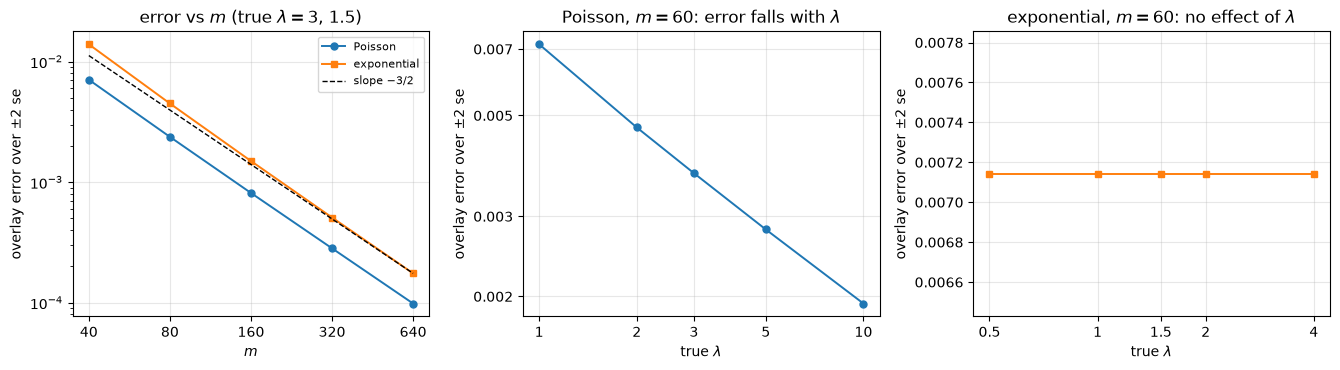

In [29]:
# Explore, part 1: error of the quadratic overlay over theta_hat +- 2 se,
# in nats per observation, as a function of m and of the true parameter.
from matplotlib.ticker import NullLocator, ScalarFormatter


def overlay_err(fun, x0, info, se, k=2.0, n=401):
    t = np.linspace(x0 - k * se, x0 + k * se, n)
    return np.abs(fun(t) - (fun(x0) - 0.5 * info * (t - x0) ** 2)).max()


def draw_23(m, lam_p_true=3.0, lam_e_true=1.5, mu_true=1.0, sig=0.8, seed=2026):
    """One sample of size m from the three regular models, plus their overlay errors."""
    u = np.random.default_rng(seed).uniform(size=int(m))
    yp = stats.poisson.ppf(u, lam_p_true)
    ye = -np.log1p(-u) / lam_e_true
    yg = mu_true + sig * stats.norm.ppf(u)
    lam_p, lam_e, mu_g = yp.mean(), 1 / ye.mean(), yg.mean()
    return (overlay_err(lambda t: ll_pois(t, yp), lam_p, 1 / lam_p, np.sqrt(lam_p / m)),
            overlay_err(lambda t: ll_exp(t, ye), lam_e, 1 / lam_e ** 2, lam_e / np.sqrt(m)),
            overlay_err(lambda t: ll_gauss_mu(t, yg, sig), mu_g, 1 / sig ** 2, sig / np.sqrt(m)))


ms = np.array([40, 80, 160, 320, 640])
reps = 40
names = ["Poisson", "exponential", "Gaussian"]
err_m = np.empty((3, ms.size))
for i, m in enumerate(ms):
    err_m[:, i] = np.mean([draw_23(m, seed=1000 + r) for r in range(reps)], axis=0)
for name, row in zip(names, err_m):
    print(f"{name:12s} " + "  ".join(f"{v:.3e}" for v in row))
for name, row in zip(names[:2], err_m[:2]):
    slope = np.polyfit(np.log(ms), np.log(row), 1)[0]
    print(f"{name:12s} log-log slope = {slope:.3f}   (cubic term: -3/2)")
    assert -1.75 < slope < -1.25
assert np.allclose(err_m[2], 0.0, atol=1e-12)
print("Gaussian: overlay error 0 at every m - the log-likelihood is exactly quadratic")

m_fix = 60
lam_p_grid = np.array([1.0, 2.0, 3.0, 5.0, 10.0])
err_p = np.array([np.mean([draw_23(m_fix, lam_p_true=lam, seed=1000 + r)[0] for r in range(reps)])
                  for lam in lam_p_grid])
lam_e_grid = np.array([0.5, 1.0, 1.5, 2.0, 4.0])
err_e = np.array([np.mean([draw_23(m_fix, lam_e_true=lam, seed=1000 + r)[1] for r in range(reps)])
                  for lam in lam_e_grid])
print("\nPoisson, m = 60: true lambda " + ", ".join(f"{v:g}" for v in lam_p_grid))
print("                overlay error " + ", ".join(f"{v:.5f}" for v in err_p))
print(f"                log-log slope in lambda = "
      f"{np.polyfit(np.log(lam_p_grid), np.log(err_p), 1)[0]:.3f}")
assert np.all(np.diff(err_p) < 0)
print("exponential, m = 60: true lambda " + ", ".join(f"{v:g}" for v in lam_e_grid))
print("                     overlay error " + ", ".join(f"{v:.8f}" for v in err_e))
print(f"                     max/min = {err_e.max() / err_e.min():.12f}"
      "   (scale family: no effect)")
assert np.allclose(err_e, err_e[0], rtol=1e-9)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
for name, row, st in zip(names[:2], err_m[:2], ("o-", "s-")):
    axes[0].loglog(ms, row, st, ms=5, lw=1.4, label=name)
axes[0].loglog(ms, err_m[1, -1] * (ms / ms[-1]) ** -1.5, "k--", lw=1.0, label=r"slope $-3/2$")
axes[0].set_xticks(ms); axes[0].set_xticklabels([f"{v:d}" for v in ms])
axes[0].xaxis.set_minor_locator(NullLocator())
axes[0].set_xlabel(r"$m$"); axes[0].set_ylabel("overlay error over $\\pm2$ se")
axes[0].set_title(r"error vs $m$ (true $\lambda=3$, $1.5$)")
axes[0].legend(fontsize=8)

axes[1].loglog(lam_p_grid, err_p, "o-", ms=5, lw=1.4)
axes[1].set_xticks(lam_p_grid); axes[1].set_xticklabels([f"{v:g}" for v in lam_p_grid])
axes[1].xaxis.set_minor_locator(NullLocator())
axes[1].set_yticks([2e-3, 3e-3, 5e-3, 7e-3])
axes[1].yaxis.set_major_formatter(ScalarFormatter())
axes[1].yaxis.set_minor_locator(NullLocator())
axes[1].set_xlabel(r"true $\lambda$"); axes[1].set_ylabel("overlay error over $\\pm2$ se")
axes[1].set_title(r"Poisson, $m=60$: error falls with $\lambda$")

axes[2].semilogx(lam_e_grid, err_e, "s-", ms=5, lw=1.4, color="tab:orange")
axes[2].set_xticks(lam_e_grid); axes[2].set_xticklabels([f"{v:g}" for v in lam_e_grid])
axes[2].xaxis.set_minor_locator(NullLocator())
axes[2].set_ylim(0.9 * err_e.min(), 1.1 * err_e.max())
axes[2].set_xlabel(r"true $\lambda$"); axes[2].set_ylabel("overlay error over $\\pm2$ se")
axes[2].set_title(r"exponential, $m=60$: no effect of $\lambda$")
plt.tight_layout()
plt.show()

In [30]:
# Explore, part 2: the same four panels with sliders for m and the true parameters.
# Every redraw re-seeds, so a given slider setting always gives the same four samples.
import ipywidgets as widgets
from ipywidgets import interact


def panel_23(m=60, lam_pois_true=3.0, lam_exp_true=1.5, th_unif_true=2.0,
             mu_true=1.0, sig_true=0.8):
    m = int(m)
    u = np.random.default_rng(2026).uniform(size=m)
    y_pois = stats.poisson.ppf(u, lam_pois_true)
    y_exp = -np.log1p(-u) / lam_exp_true
    y_unif = th_unif_true * u
    y_gauss = mu_true + sig_true * stats.norm.ppf(u)

    lam_p, lam_e = y_pois.mean(), 1 / y_exp.mean()
    th_u, mu_g = y_unif.max(), y_gauss.mean()
    se_p, se_e, se_g = np.sqrt(lam_p / m), lam_e / np.sqrt(m), sig_true / np.sqrt(m)

    fig, axes = plt.subplots(2, 2, figsize=(11.5, 6.6))

    g = np.linspace(lam_p - 4 * se_p, lam_p + 4 * se_p, 400)
    axes[0, 0].plot(g, ll_pois(g, y_pois), lw=1.8, label=r"$\ell/m$")
    axes[0, 0].plot(g, ll_pois(lam_p, y_pois) - 0.5 / lam_p * (g - lam_p) ** 2,
                    "k--", lw=1.2, label="quadratic")
    axes[0, 0].plot(lam_p, ll_pois(lam_p, y_pois), "o", color="k", ms=5, label="ML")
    axes[0, 0].plot(lam_pois_true, ll_pois(lam_pois_true, y_pois), "s", color="tab:red",
                    ms=5, label="true")
    axes[0, 0].set_xlabel(r"$\lambda$"); axes[0, 0].set_ylabel(r"$\ell/m$")
    axes[0, 0].set_title(rf"Poisson, true $\lambda$ = {lam_pois_true:g}")
    axes[0, 0].legend(fontsize=8)

    g = np.linspace(lam_e - 4 * se_e, lam_e + 4 * se_e, 400)
    axes[0, 1].plot(g, ll_exp(g, y_exp), lw=1.8, label=r"$\ell/m$")
    axes[0, 1].plot(g, ll_exp(lam_e, y_exp) - 0.5 / lam_e ** 2 * (g - lam_e) ** 2,
                    "k--", lw=1.2, label="quadratic")
    axes[0, 1].plot(lam_e, ll_exp(lam_e, y_exp), "o", color="k", ms=5, label="ML")
    axes[0, 1].plot(lam_exp_true, ll_exp(lam_exp_true, y_exp), "s", color="tab:red",
                    ms=5, label="true")
    axes[0, 1].set_xlabel(r"$\lambda$"); axes[0, 1].set_ylabel(r"$\ell/m$")
    axes[0, 1].set_title(rf"exponential, true $\lambda$ = {lam_exp_true:g}")
    axes[0, 1].legend(fontsize=8)

    g = np.linspace(th_u, 1.3 * th_u, 400)
    axes[1, 0].plot(g, ll_unif(g, y_unif), lw=1.8, label=r"$\ell/m$")
    axes[1, 0].plot(th_u, ll_unif(th_u, y_unif), "o", color="k", ms=5, label="ML")
    axes[1, 0].plot(th_unif_true, ll_unif(th_unif_true, y_unif), "s", color="tab:red",
                    ms=5, label="true")
    axes[1, 0].axvline(th_u, color="k", lw=0.8, ls=":")
    axes[1, 0].annotate(r"$-\infty$ for $\theta<\hat\theta$",
                        xy=(th_u, ll_unif(th_u, y_unif)),
                        xytext=(th_u * 1.04, ll_unif(1.2 * th_u, y_unif)),
                        arrowprops=dict(arrowstyle="->", lw=0.8), fontsize=8)
    axes[1, 0].set_xlabel(r"$\theta$"); axes[1, 0].set_ylabel(r"$\ell/m$")
    axes[1, 0].set_title(rf"uniform on $[0,\theta]$, true $\theta$ = {th_unif_true:g}")
    axes[1, 0].legend(fontsize=8)

    g = np.linspace(mu_g - 4 * se_g, mu_g + 4 * se_g, 400)
    axes[1, 1].plot(g, ll_gauss_mu(g, y_gauss, sig_true), lw=1.8, label=r"$\ell/m$")
    axes[1, 1].plot(g, ll_gauss_mu(mu_g, y_gauss, sig_true)
                    - 0.5 / sig_true ** 2 * (g - mu_g) ** 2,
                    "k--", lw=1.2, label="quadratic")
    axes[1, 1].plot(mu_g, ll_gauss_mu(mu_g, y_gauss, sig_true), "o", color="k", ms=5,
                    label="ML")
    axes[1, 1].plot(mu_true, ll_gauss_mu(mu_true, y_gauss, sig_true), "s",
                    color="tab:red", ms=5, label="true")
    axes[1, 1].set_xlabel(r"$\mu$"); axes[1, 1].set_ylabel(r"$\ell/m$")
    axes[1, 1].set_title(rf"Gaussian, true $\mu$ = {mu_true:g}, $\sigma$ = {sig_true:g}")
    axes[1, 1].legend(fontsize=8)

    fig.suptitle(rf"$m$ = {m}", y=0.995)
    plt.tight_layout()
    plt.show()


def _slider(desc, lo, hi, step, val):
    return widgets.FloatSlider(value=val, min=lo, max=hi, step=step, description=desc,
                               continuous_update=False,
                               layout=widgets.Layout(width="340px"))


interact(panel_23,
         m=widgets.IntSlider(value=60, min=10, max=400, step=10, description="m",
                             continuous_update=False,
                             layout=widgets.Layout(width="340px")),
         lam_pois_true=_slider("Poisson λ", 0.5, 8.0, 0.1, 3.0),
         lam_exp_true=_slider("exp. λ", 0.3, 4.0, 0.1, 1.5),
         th_unif_true=_slider("unif. θ", 0.5, 4.0, 0.1, 2.0),
         mu_true=_slider("Gauss μ", -2.0, 4.0, 0.1, 1.0),
         sig_true=_slider("Gauss σ", 0.2, 2.0, 0.1, 0.8));

interactive(children=(IntSlider(value=60, continuous_update=False, description='m', layout=Layout(width='340px…

### Explain

The uniform model is the one whose log-likelihood is not differentiable at its
maximum. There $\ell/m=-\log\theta$ for $\theta\ge\max_i y_i$ and $-\infty$
below.

The quadratic approximation is exact for the Gaussian since $\ell$ is exactly quadratic in $\mu$ and good
near the maximum for the Poisson and exponential models, it is visibly asymmetric for the exponential.


## 2.4 Multivariate Gaussian [MLE 1.3.7]

### Task

Sample $m$ points from a 2-D Gaussian (reuse the $\Sigma=Q\Lambda Q^\top$
construction from the Linear Algebra portfolio). Compute $\hat\mu_{\mathrm{ML}}$
and $\hat\Sigma_{\mathrm{ML}}$ and check them against `np.mean` and
`np.cov(..., bias=True)`. Plot the log-likelihood as a function of $\mu$ (with
$\Sigma=\hat\Sigma_{\mathrm{ML}}$ fixed) as a contour map.

$$\ell(\mu,\Sigma)=-\frac{mn}{2}\log(2\pi)-\frac{m}{2}\log|\Sigma|
-\frac12\sum_i(y_i-\mu)^\top\Sigma^{-1}(y_i-\mu)$$

The matrix-derivative identities of [MLE 1.3.7] are verified by finite
differences below, and $\ell$ is rewritten in terms of the precision matrix
$\Theta=\Sigma^{-1}$ (kept for Exercise 4.5).

In [31]:
m4 = 200
mu_true4 = np.array([1.0, -2.0])
Q, _ = np.linalg.qr(rng.normal(size=(2, 2)))
lam_true4 = np.array([4.0, 0.5])
Sigma_true4 = Q @ np.diag(lam_true4) @ Q.T
Y = rng.multivariate_normal(mu_true4, Sigma_true4, size=m4)

mu_ml = Y.mean(axis=0)
Sigma_ml = np.cov(Y, rowvar=False, bias=True)
D = Y - mu_ml
S = D.T @ D
print("mu_hat_ML:", np.round(mu_ml, 4), " true:", mu_true4)
print("Sigma_hat_ML:\n", np.round(Sigma_ml, 4))
print("eigenvalues of Sigma_hat_ML:", np.round(np.linalg.eigvalsh(Sigma_ml), 4),
      " true:", lam_true4)
print("max |Sigma_hat - S/m| =", np.abs(Sigma_ml - S / m4).max())
assert np.allclose(Sigma_ml, S / m4)
assert np.allclose(mu_ml, np.mean(Y, axis=0))
assert np.allclose(Sigma_ml, np.cov(Y, rowvar=False, bias=True))
assert np.allclose(np.cov(Y, rowvar=False, bias=False), m4 / (m4 - 1) * Sigma_ml)


def loglik_mvn(mu, Sigma, Y):
    n = Y.shape[1]
    mm = Y.shape[0]
    d = Y - mu
    quad = np.einsum("ij,jk,ik->i", d, np.linalg.inv(Sigma), d)
    return (-0.5 * mm * n * np.log(2 * np.pi)
            - 0.5 * mm * np.linalg.slogdet(Sigma)[1] - 0.5 * quad.sum())


def grad_mu_mvn(mu, Sigma, Y):
    return np.linalg.inv(Sigma) @ (Y - mu).sum(axis=0)


def grad_sigma_mvn(mu, Sigma, Y):
    d = Y - mu
    Si = np.linalg.inv(Sigma)
    return -0.5 * Y.shape[0] * Si + 0.5 * Si @ (d.T @ d) @ Si


assert np.allclose(grad_mu_mvn(mu_ml, Sigma_ml, Y), 0, atol=1e-8)
assert np.allclose(grad_sigma_mvn(mu_ml, Sigma_ml, Y), 0, atol=1e-8)
print("gradient wrt mu at the ML point:", grad_mu_mvn(mu_ml, Sigma_ml, Y))
print("gradient wrt Sigma at the ML point:\n", grad_sigma_mvn(mu_ml, Sigma_ml, Y))

# finite differences, at a point away from the ML estimate
mu_t = mu_ml + np.array([0.4, -0.3])
Sigma_t = 1.25 * Sigma_ml


def sym_basis(i, j):
    E = np.zeros((2, 2))
    if i == j:
        E[i, i] = 1.0
    else:
        E[i, j] = E[j, i] = 0.5
    return E


h = 1e-6
G = grad_sigma_mvn(mu_t, Sigma_t, Y)
err_S = 0.0
for i in range(2):
    for j in range(i, 2):
        E = sym_basis(i, j)
        fd = (loglik_mvn(mu_t, Sigma_t + h * E, Y)
              - loglik_mvn(mu_t, Sigma_t - h * E, Y)) / (2 * h)
        err_S = max(err_S, abs(fd - G[i, j]))
g = grad_mu_mvn(mu_t, Sigma_t, Y)
err_mu = max(abs((loglik_mvn(mu_t + h * e, Sigma_t, Y)
                  - loglik_mvn(mu_t - h * e, Sigma_t, Y)) / (2 * h) - g[i])
             for i, e in enumerate(np.eye(2)))
print(f"max finite-difference error: d/dSigma {err_S:.2e}, d/dmu {err_mu:.2e}")
assert err_S < 1e-5 and err_mu < 1e-5

mu_hat_ML: [ 1.1612 -1.9968]  true: [ 1. -2.]
Sigma_hat_ML:
 [[ 0.7489 -0.8139]
 [-0.8139  3.5452]]
eigenvalues of Sigma_hat_ML: [0.5292 3.7649]  true: [4.  0.5]
max |Sigma_hat - S/m| = 0.0
gradient wrt mu at the ML point: [1.26322740e-13 6.35754228e-14]
gradient wrt Sigma at the ML point:
 [[-2.84217094e-14  7.10542736e-15]
 [-7.10542736e-15  0.00000000e+00]]
max finite-difference error: d/dSigma 4.99e-08, d/dmu 4.39e-08


In [32]:
# precision matrix: ell(mu_hat, Theta) = (m/2) log det Theta - (1/2) tr(Theta S) + const
Theta = np.linalg.inv(Sigma_t)
ell_prec = (0.5 * m4 * np.linalg.slogdet(Theta)[1] - 0.5 * np.trace(Theta @ S)
            - 0.5 * m4 * 2 * np.log(2 * np.pi))
print("precision form:", ell_prec, " direct:", loglik_mvn(mu_ml, Sigma_t, Y))
assert np.isclose(ell_prec, loglik_mvn(mu_ml, Sigma_t, Y))

# level sets of ell(mu) are ellipses: axes along the eigenvectors of Sigma_hat
evals, evecs = np.linalg.eigh(Sigma_ml)
Delta = 2.0
semi = np.sqrt(2 * Delta * evals / m4)
for k in range(2):
    for s in (+1, -1):
        p = mu_ml + s * semi[k] * evecs[:, k]
        assert np.isclose(loglik_mvn(p, Sigma_ml, Y),
                          loglik_mvn(mu_ml, Sigma_ml, Y) - Delta, atol=1e-8)
print("eigenvalues of Sigma_hat_ML:", np.round(evals, 4))
print(f"semi-axes of the level set at Delta = {Delta}:", np.round(semi, 4))

precision form: -641.1411182681861  direct: -641.141118268186
eigenvalues of Sigma_hat_ML: [0.5292 3.7649]
semi-axes of the level set at Delta = 2.0: [0.1029 0.2744]


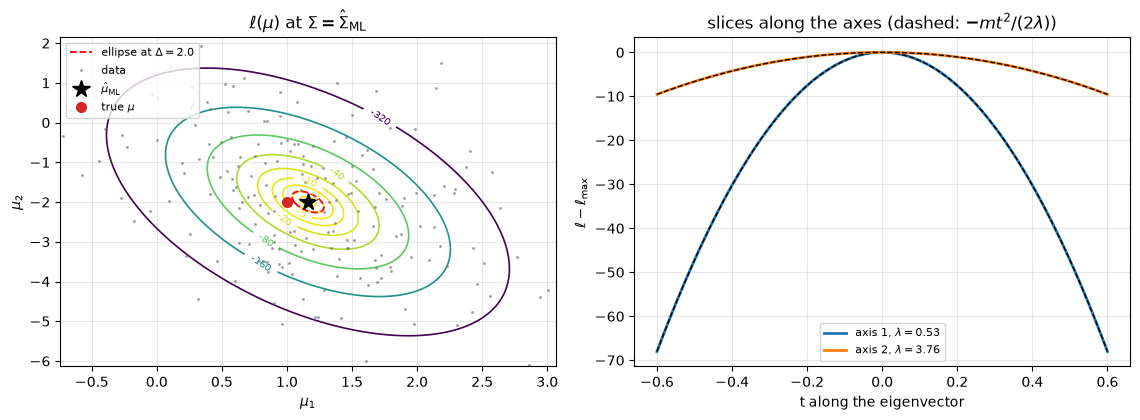

In [33]:
Lmax = loglik_mvn(mu_ml, Sigma_ml, Y)
sd = np.sqrt(np.diag(Sigma_ml))
xr = np.linspace(mu_ml[0] - 2.2 * sd[0], mu_ml[0] + 2.2 * sd[0], 300)
yr = np.linspace(mu_ml[1] - 2.2 * sd[1], mu_ml[1] + 2.2 * sd[1], 300)
MU0, MU1 = np.meshgrid(xr, yr, indexing="ij")
L = np.array([[loglik_mvn(np.array([a, b]), Sigma_ml, Y) for b in yr] for a in xr])

Deltas = np.array([0.5, 2.0, 5.0, 10.0, 20.0, 40.0, 80.0, 160.0, 320.0])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
cs = axes[0].contour(MU0, MU1, L - Lmax, levels=-Deltas[::-1], cmap="viridis",
                     linewidths=1.2)
axes[0].clabel(cs, inline=True, fontsize=7, fmt="%g")
th = np.linspace(0, 2 * np.pi, 300)
D0 = 2.0
ell = (mu_ml[:, None]
       + np.sqrt(2 * D0 / m4) * (np.sqrt(evals[0]) * np.outer(evecs[:, 0], np.cos(th))
                                 + np.sqrt(evals[1]) * np.outer(evecs[:, 1], np.sin(th))))
axes[0].plot(ell[0], ell[1], "r--", lw=1.3, label=rf"ellipse at $\Delta={D0}$")
axes[0].plot(Y[:, 0], Y[:, 1], ".", color="0.45", ms=2.5, alpha=0.5, label="data")
axes[0].plot(*mu_ml, "k*", ms=13, label=r"$\hat\mu_{\rm ML}$")
axes[0].plot(*mu_true4, "o", color="tab:red", ms=7, label=r"true $\mu$")
axes[0].set_xlim(xr[0], xr[-1]); axes[0].set_ylim(yr[0], yr[-1])
axes[0].set_xlabel(r"$\mu_1$"); axes[0].set_ylabel(r"$\mu_2$")
axes[0].set_title(r"$\ell(\mu)$ at $\Sigma=\hat\Sigma_{\rm ML}$")
axes[0].legend(fontsize=8, loc="upper left")

t = np.linspace(-0.6, 0.6, 400)
for k, col in zip(range(2), ["tab:blue", "tab:orange"]):
    pts = mu_ml + t[:, None] * evecs[:, k]
    vals = np.array([loglik_mvn(p, Sigma_ml, Y) for p in pts])
    axes[1].plot(t, vals - Lmax, col, lw=2.0,
                 label=rf"axis {k + 1}, $\lambda={evals[k]:.2f}$")
    axes[1].plot(t, -0.5 * m4 * t ** 2 / evals[k], "k--", lw=1.0)
axes[1].set_xlabel("t along the eigenvector"); axes[1].set_ylabel(r"$\ell-\ell_{\max}$")
axes[1].set_title(r"slices along the axes (dashed: $-mt^2/(2\lambda)$)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Explain

At fixed $\Sigma=\hat\Sigma_{\mathrm{ML}}$ the log-likelihood is
$\ell(\mu)=\ell(\hat\mu)-\frac{m}{2}(\mu-\hat\mu)^\top\hat\Sigma_{\mathrm{ML}}^{-1}(\mu-\hat\mu)$,
so its level sets are ellipses centred at $\hat\mu_{\mathrm{ML}}$, with axes
along the eigenvectors of $\hat\Sigma_{\mathrm{ML}}$.

The matrix derivatives of [MLE 1.3.7] check out: with symmetric perturbations
$E_{ij}$, the directional derivative of $\ell$ in $\Sigma$ matches
$\mathrm{tr}(G_\Sigma^\top E_{ij})$ to $4.99\times10^{-8}$ and the $\mu$
derivative to $4.39\times10^{-8}$, and both gradients vanish at
$(\hat\mu_{\mathrm{ML}},\hat\Sigma_{\mathrm{ML}})$ to $10^{-13}$. The $\log\det\Theta$ part is the
$(m/2)\log\det\Theta$ term, and $\mathrm{tr}(\Theta S)$ enters with the factor
$-\frac12$ — the form kept for Exercise 4.5.


## 2.5 ML linear regression is least squares [MLE 1.6.2]

### Task

Generate $y_i=2+0.5x_i+\varepsilon_i$ with $\varepsilon_i\sim N(0,\sigma^2)$.
Plot the log-likelihood $\ell(\beta_0,\beta_1)$ for fixed $\sigma^2$, and the
cost $\|y-X\beta\|_2^2$, side by side. Mark $\hat\beta_{\mathrm{ML}}$ and
$\hat\beta_{\mathrm{OLS}}=(X^\top X)^{-1}X^\top y$.

In [34]:
m5 = 20
x = np.sort(rng.uniform(0, 10, size=m5))
X = np.column_stack([np.ones(m5), x])
beta_true = np.array([2.0, 0.5])
sigma2 = 1.0
y5 = X @ beta_true + rng.normal(0, np.sqrt(sigma2), size=m5)

beta_ols = np.linalg.solve(X.T @ X, X.T @ y5)
rss = lambda b: np.sum((y5 - X @ b) ** 2)
beta_ml = minimize(lambda b: rss(b), x0=[0.0, 0.0], method="BFGS",
                   options={"gtol": 1e-12}).x
print("beta_OLS:", np.round(beta_ols, 4), " beta_ML:", np.round(beta_ml, 4))
assert np.allclose(beta_ml, beta_ols, atol=1e-5)

# the maximiser does not move when sigma^2 changes
for s2 in [0.25, 1.0, 4.0, 25.0]:
    negll = lambda b: 0.5 * m5 * np.log(2 * np.pi * s2) + rss(b) / (2 * s2)
    b = minimize(negll, x0=[0.0, 0.0], method="BFGS", options={"gtol": 1e-12}).x
    print(f"sigma^2 = {s2:5.2f}: argmax {np.round(b, 5)}"
          f"  max|diff to OLS| = {np.abs(b - beta_ols).max():.1e}")
    assert np.allclose(b, beta_ols, atol=1e-5)

rss_min = rss(beta_ols)
var_ml = rss_min / m5
var_unb = rss_min / (m5 - 2)
print(f"RSS = {rss_min:.4f}   sigma^2_ML = {var_ml:.4f}   unbiased = {var_unb:.4f}")
assert np.isclose(var_ml, np.sum((y5 - X @ beta_ols) ** 2) / m5)
assert np.isclose(var_unb, var_ml * m5 / (m5 - 2))

beta_OLS: [2.2535 0.4491]  beta_ML: [2.2535 0.4491]
sigma^2 =  0.25: argmax [2.25354 0.44905]  max|diff to OLS| = 1.0e-07
sigma^2 =  1.00: argmax [2.25354 0.44905]  max|diff to OLS| = 9.2e-08
sigma^2 =  4.00: argmax [2.25354 0.44905]  max|diff to OLS| = 5.9e-08
sigma^2 = 25.00: argmax [2.25354 0.44905]  max|diff to OLS| = 3.3e-07
RSS = 16.5185   sigma^2_ML = 0.8259   unbiased = 0.9177


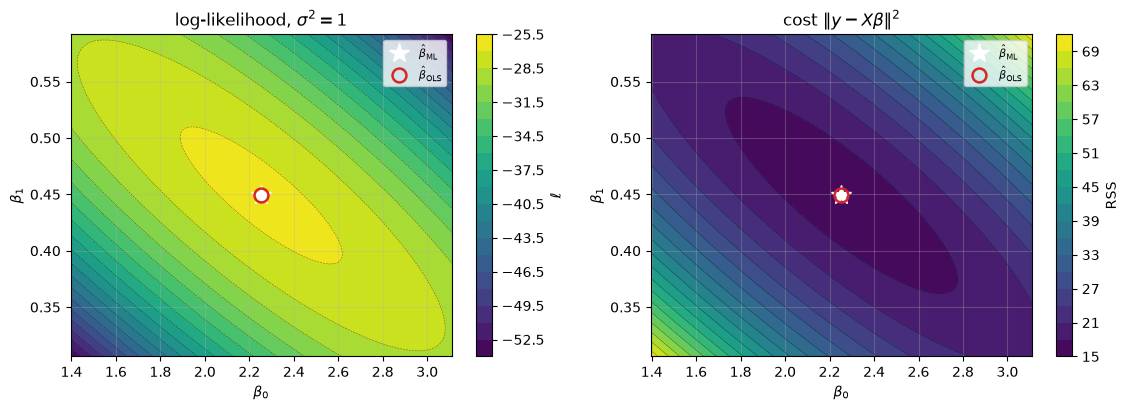

In [35]:
se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)))   # with sigma^2 = 1
b0 = np.linspace(beta_ols[0] - 2 * se[0], beta_ols[0] + 2 * se[0], 300)
b1 = np.linspace(beta_ols[1] - 2 * se[1], beta_ols[1] + 2 * se[1], 300)
B0, B1 = np.meshgrid(b0, b1, indexing="ij")
R = np.array([[(y5 - X @ np.array([a, bb])).dot(y5 - X @ np.array([a, bb]))
               for bb in b1] for a in b0])
LL = -0.5 * m5 * np.log(2 * np.pi * sigma2) - R / (2 * sigma2)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, Z, ttl, cb in [(axes[0], LL, r"log-likelihood, $\sigma^2=1$", r"$\ell$"),
                       (axes[1], R, r"cost $\|y-X\beta\|^2$", "RSS")]:
    cs = ax.contourf(B0, B1, Z, levels=20, cmap="viridis")
    ax.contour(B0, B1, Z, levels=20, colors="k", linewidths=0.4, alpha=0.5)
    fig.colorbar(cs, ax=ax, label=cb)
    ax.plot(*beta_ml, "w*", ms=15, label=r"$\hat\beta_{\rm ML}$")
    ax.plot(*beta_ols, "o", mfc="none", mec="tab:red", ms=10, mew=1.8,
            label=r"$\hat\beta_{\rm OLS}$")
    ax.set_xlabel(r"$\beta_0$"); ax.set_ylabel(r"$\beta_1$"); ax.set_title(ttl)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

L1 (LP): [2.4931 0.4321]  Nelder-Mead: [2.4931 0.4321]
OLS on the same Laplace data: [2.2826 0.4356]
max |L1 - OLS| = 0.2105
sum |residual| at L1: 16.3792   at OLS: 16.7916


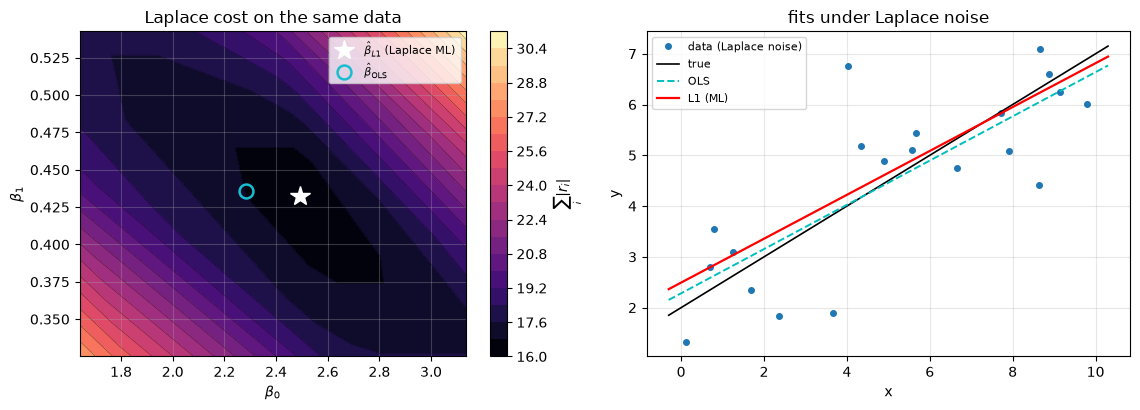

In [36]:
# Laplace noise: the ML criterion becomes the sum of absolute residuals
y_l = X @ beta_true + rng.laplace(0, 1.0, size=m5)
beta_ols_l = np.linalg.solve(X.T @ X, X.T @ y_l)

c = np.concatenate([np.zeros(2), np.ones(m5)])
A_ub = np.vstack([np.hstack([-X, -np.eye(m5)]), np.hstack([X, -np.eye(m5)])])
res = linprog(c, A_ub=A_ub, b_ub=np.concatenate([-y_l, y_l]),
              bounds=[(None, None), (None, None)] + [(0, None)] * m5, method="highs")
assert res.success
beta_l1 = res.x[:2]

# the same L1 minimum from a general-purpose optimiser
lad = minimize(lambda b: np.sum(np.abs(y_l - X @ b)), x0=beta_ols_l, method="Nelder-Mead",
               options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 20000, "maxfev": 20000})
print("L1 (LP):", np.round(beta_l1, 4), " Nelder-Mead:", np.round(lad.x, 4))
assert np.allclose(lad.x, beta_l1, atol=1e-5)

print("OLS on the same Laplace data:", np.round(beta_ols_l, 4))
print(f"max |L1 - OLS| = {np.abs(beta_l1 - beta_ols_l).max():.4f}")
print(f"sum |residual| at L1: {np.sum(np.abs(y_l - X @ beta_l1)):.4f}"
      f"   at OLS: {np.sum(np.abs(y_l - X @ beta_ols_l)):.4f}")
assert np.abs(beta_l1 - beta_ols_l).max() > 0.05
assert np.sum(np.abs(y_l - X @ beta_l1)) < np.sum(np.abs(y_l - X @ beta_ols_l))

lo0, hi0 = min(beta_l1[0], beta_ols_l[0]), max(beta_l1[0], beta_ols_l[0])
lo1, hi1 = min(beta_l1[1], beta_ols_l[1]), max(beta_l1[1], beta_ols_l[1])
c0 = np.linspace(lo0 - 1.5 * se[0], hi0 + 1.5 * se[0], 300)
c1 = np.linspace(lo1 - 1.5 * se[1], hi1 + 1.5 * se[1], 300)
C0, C1 = np.meshgrid(c0, c1, indexing="ij")
L1c = np.array([[np.sum(np.abs(y_l - X @ np.array([a, bb]))) for bb in c1] for a in c0])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
cs = axes[0].contourf(C0, C1, L1c, levels=20, cmap="magma")
axes[0].contour(C0, C1, L1c, levels=20, colors="k", linewidths=0.4, alpha=0.5)
fig.colorbar(cs, ax=axes[0], label=r"$\sum_i|r_i|$")
axes[0].plot(*beta_l1, "w*", ms=15, label=r"$\hat\beta_{L1}$ (Laplace ML)")
axes[0].plot(*beta_ols_l, "o", mfc="none", mec="tab:cyan", ms=10, mew=1.8,
             label=r"$\hat\beta_{\rm OLS}$")
axes[0].set_xlabel(r"$\beta_0$"); axes[0].set_ylabel(r"$\beta_1$")
axes[0].set_title("Laplace cost on the same data"); axes[0].legend(fontsize=8)

xx = np.linspace(-0.3, 10.3, 10)
axes[1].plot(x, y_l, "o", ms=4, label="data (Laplace noise)")
axes[1].plot(xx, beta_true[0] + beta_true[1] * xx, "k-", lw=1.2, label="true")
axes[1].plot(xx, beta_ols_l[0] + beta_ols_l[1] * xx, "c--", lw=1.4, label="OLS")
axes[1].plot(xx, beta_l1[0] + beta_l1[1] * xx, "r-", lw=1.6, label="L1 (ML)")
axes[1].set_xlabel("x"); axes[1].set_ylabel("y"); axes[1].legend(fontsize=8)
axes[1].set_title("fits under Laplace noise")
plt.tight_layout()
plt.show()

### Explain

Both panels have the same maximiser/minimiser for any $\sigma^2$ because
$\ell(\beta,\sigma^2)=-\frac{m}{2}\log(2\pi\sigma^2)-\frac{1}{2\sigma^2}\|y-X\beta\|^2$,
$\sigma^2>0$ only rescales the quadratic, so
$\arg\max_\beta\ell=\arg\min_\beta\|y-X\beta\|^2$. 

With Laplace noise, $f(\varepsilon)=\frac{1}{2b}e^{-|\varepsilon|/b}$, the
log-likelihood becomes
$\ell(\beta,b)=-m\log(2b)-\frac{1}{b}\sum_i|y_i-x_i^\top\beta|$, so the ML
estimate minimises the sum of absolute residuals (L1, least absolute
deviations) instead of the sum of squares.
